# SpaceGuard AI — ML Phase 2B: NASA SMAP/MSL Exploratory Data Analysis

> **Status:** Research & Exploratory Data Analysis (EDA) Only  
> **Notice:** **NO MACHINE LEARNING MODEL HAS BEEN TRAINED.**  
> No Isolation Forest, LSTM, Autoencoder, or classifier is trained. This notebook performs a scientific, read-only analysis of the NASA SMAP and MSL benchmark telemetry datasets to establish empirical foundations for future feature engineering and evaluation.

## 1. Environment & Dataset Paths

In [1]:
import os
import sys
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure consistent style
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.figsize"] = (12, 4)
plt.rcParams["font.sans-serif"] = "DejaVu Sans"

# Locate raw dataset and manifest
base_dir = Path.cwd().resolve()
if base_dir.name == "notebooks":
    base_dir = base_dir.parent

raw_dir = base_dir / "data" / "raw" / "nasa_smap_msl"
manifest_path = base_dir / "data" / "DATASET_MANIFEST.json"

print(f"Python Executable : {sys.executable}")
print(f"Raw dataset path  : {raw_dir}")
print(f"Directory exists  : {raw_dir.exists()}")

assert raw_dir.exists(), f"Raw directory {raw_dir} does not exist!"
assert manifest_path.exists(), f"Manifest {manifest_path} does not exist!"

Python Executable : C:\Users\Aman\OneDrive\Desktop\SpaceGaurd\ml-service\.venv\Scripts\python.exe
Raw dataset path  : C:\Users\Aman\OneDrive\Desktop\SpaceGaurd\ml-service\data\raw\nasa_smap_msl
Directory exists  : True


## 2. Dataset Loading (Safe, Read-Only)

Load arrays without in-place modification. The raw dataset remains immutable.

In [2]:
# Load MSL arrays
msl_train = np.load(raw_dir / "MSL_train.npy")
msl_test = np.load(raw_dir / "MSL_test.npy")
msl_test_label = np.load(raw_dir / "MSL_test_label.npy")

# Load SMAP arrays
smap_train = np.load(raw_dir / "SMAP_train.npy")
smap_test = np.load(raw_dir / "SMAP_test.npy")
smap_test_label = np.load(raw_dir / "SMAP_test_label.npy")

# Load ground-truth annotation catalog
df_labels = pd.read_csv(raw_dir / "labeled_anomalies.csv")

print("[OK] All 7 files loaded successfully into memory.")

[OK] All 7 files loaded successfully into memory.


## 3. Shape, Dimensions & Memory Footprint Inspection

Determine shapes, dtypes, channel counts, observation counts, and memory footprints.

In [3]:
def summarize_dataset(name, train, test, label):
    mem_mb = (train.nbytes + test.nbytes + label.nbytes) / (1024 * 1024)
    return {
        "Dataset": name,
        "Train Shape": str(train.shape),
        "Test Shape": str(test.shape),
        "Label Shape": str(label.shape),
        "Channels": train.shape[1],
        "Train Samples": train.shape[0],
        "Test Samples": test.shape[0],
        "Total Observations": train.shape[0] + test.shape[0],
        "Train Dtype": str(train.dtype),
        "Label Dtype": str(label.dtype),
        "Memory Footprint (MB)": f"{mem_mb:.2f} MB"
    }

df_structure = pd.DataFrame([
    summarize_dataset("Mars Science Laboratory (MSL)", msl_train, msl_test, msl_test_label),
    summarize_dataset("Soil Moisture Active Passive (SMAP)", smap_train, smap_test, smap_test_label)
])

df_structure.set_index("Dataset").T

Dataset,Mars Science Laboratory (MSL),Soil Moisture Active Passive (SMAP)
Train Shape,"(58317, 55)","(135183, 25)"
Test Shape,"(73729, 55)","(427617, 25)"
Label Shape,"(73729,)","(427617,)"
Channels,55,25
Train Samples,58317,135183
Test Samples,73729,427617
Total Observations,132046,562800
Train Dtype,float64,float64
Label Dtype,bool,bool
Memory Footprint (MB),55.48 MB,107.75 MB


## 4. Missingness & Data Integrity Audit

Audit for NaNs, positive/negative infinities, constant/near-constant channels, and label integrity.

In [4]:
def check_integrity(name, train, test, label):
    nan_train = int(np.isnan(train).sum())
    nan_test = int(np.isnan(test).sum())
    inf_train = int(np.isinf(train).sum())
    inf_test = int(np.isinf(test).sum())
    
    train_stds = train.std(axis=0)
    test_stds = test.std(axis=0)
    
    zero_var_train = int((train_stds == 0.0).sum())
    zero_var_test = int((test_stds == 0.0).sum())
    near_const_train = int(((train_stds > 0.0) & (train_stds < 1e-4)).sum())
    
    label_match = (len(label) == len(test))
    invalid_labels = int((~np.isin(label, [True, False])).sum())
    
    return {
        "Dataset": name,
        "Train NaNs": nan_train,
        "Test NaNs": nan_test,
        "Train Infs": inf_train,
        "Test Infs": inf_test,
        "Zero-Var Channels (Train)": zero_var_train,
        "Zero-Var Channels (Test)": zero_var_test,
        "Near-Constant (<1e-4)": near_const_train,
        "Label Length Matches Test": label_match,
        "Invalid Labels": invalid_labels
    }

df_integrity = pd.DataFrame([
    check_integrity("MSL", msl_train, msl_test, msl_test_label),
    check_integrity("SMAP", smap_train, smap_test, smap_test_label)
])

df_integrity.set_index("Dataset").T

Dataset,MSL,SMAP
Train NaNs,0,0
Test NaNs,0,0
Train Infs,0,0
Test Infs,0,0
Zero-Var Channels (Train),22,1
Zero-Var Channels (Test),21,0
Near-Constant (<1e-4),0,0
Label Length Matches Test,True,True
Invalid Labels,0,0


### Data Integrity Observation:
- **Zero NaNs and Zero Infs**: Both datasets are clean floating-point matrices without missing indicators.
- **Constant Channels in MSL**: MSL contains 22 channels (out of 55) in the train set that have exactly zero variance (`std = 0.0`). As documented in Hundman et al. (2018), features beyond channel 0 represent one-hot encoded spacecraft commands. Inactive commands during nominal segments remain 0 constantly.

## 5. Descriptive Statistics

Calculate summary statistics across all channels: count, mean, standard deviation, minimum, 1st percentile, 25th percentile, median, 75th percentile, 99th percentile, and maximum.

In [5]:
def compute_descriptive_stats(arr, dataset_prefix):
    rows = []
    n_channels = arr.shape[1]
    for col in range(n_channels):
        vals = arr[:, col]
        q1, median, q3 = np.percentile(vals, [25, 50, 75])
        p1, p99 = np.percentile(vals, [1, 99])
        rows.append({
            "channel": f"{dataset_prefix}_col_{col:02d}",
            "count": len(vals),
            "mean": float(vals.mean()),
            "std": float(vals.std()),
            "min": float(vals.min()),
            "p01": float(p1),
            "p25": float(q1),
            "median": float(median),
            "p75": float(q3),
            "p99": float(p99),
            "max": float(vals.max())
        })
    return pd.DataFrame(rows)

df_msl_stats = compute_descriptive_stats(msl_train, "MSL_train")
df_smap_stats = compute_descriptive_stats(smap_train, "SMAP_train")

print("Top 5 Channels by Variance - MSL Train:")
display(df_msl_stats.sort_values(by="std", ascending=False).head(5))

print("\nTop 5 Channels by Variance - SMAP Train:")
display(df_smap_stats.sort_values(by="std", ascending=False).head(5))

Top 5 Channels by Variance - MSL Train:


,channel,count,mean,std,min,p01,p25,median,p75,p99,max
0,MSL_train_col_00,58317,-0.088911,0.904969,-1.477217,-1.089725,-1.0,-0.451955,0.960276,1.089773,4.162651
5,MSL_train_col_05,58317,0.085807,0.280079,0.000000,0.000000,0.0,0.000000,0.000000,1.000000,1.000000
11,MSL_train_col_11,58317,0.029100,0.168086,0.000000,0.000000,0.0,0.000000,0.000000,1.000000,1.000000
33,MSL_train_col_33,58317,0.027711,0.164142,0.000000,0.000000,0.0,0.000000,0.000000,1.000000,1.000000
14,MSL_train_col_14,58317,0.017096,0.129630,0.000000,0.000000,0.0,0.000000,0.000000,1.000000,1.000000



Top 5 Channels by Variance - SMAP Train:


,channel,count,mean,std,min,p01,p25,median,p75,p99,max
0,SMAP_train_col_00,135183,-0.186839,0.788575,-1.0,-1.0,-1.0,-0.373494,0.664939,1.0,1.0
5,SMAP_train_col_05,135183,0.128078,0.334177,0.0,0.0,0.0,0.000000,0.000000,1.0,1.0
6,SMAP_train_col_06,135183,0.098008,0.297325,0.0,0.0,0.0,0.000000,0.000000,1.0,1.0
21,SMAP_train_col_21,135183,0.028798,0.167238,0.0,0.0,0.0,0.000000,0.000000,1.0,1.0
1,SMAP_train_col_01,135183,0.027563,0.163716,0.0,0.0,0.0,0.000000,0.000000,1.0,1.0


## 6. Distribution Analysis

Inspect empirical histograms and box plots for representative channels (selected by variance: primary telemetry channel 0, secondary telemetry channels, and low-variance commands).

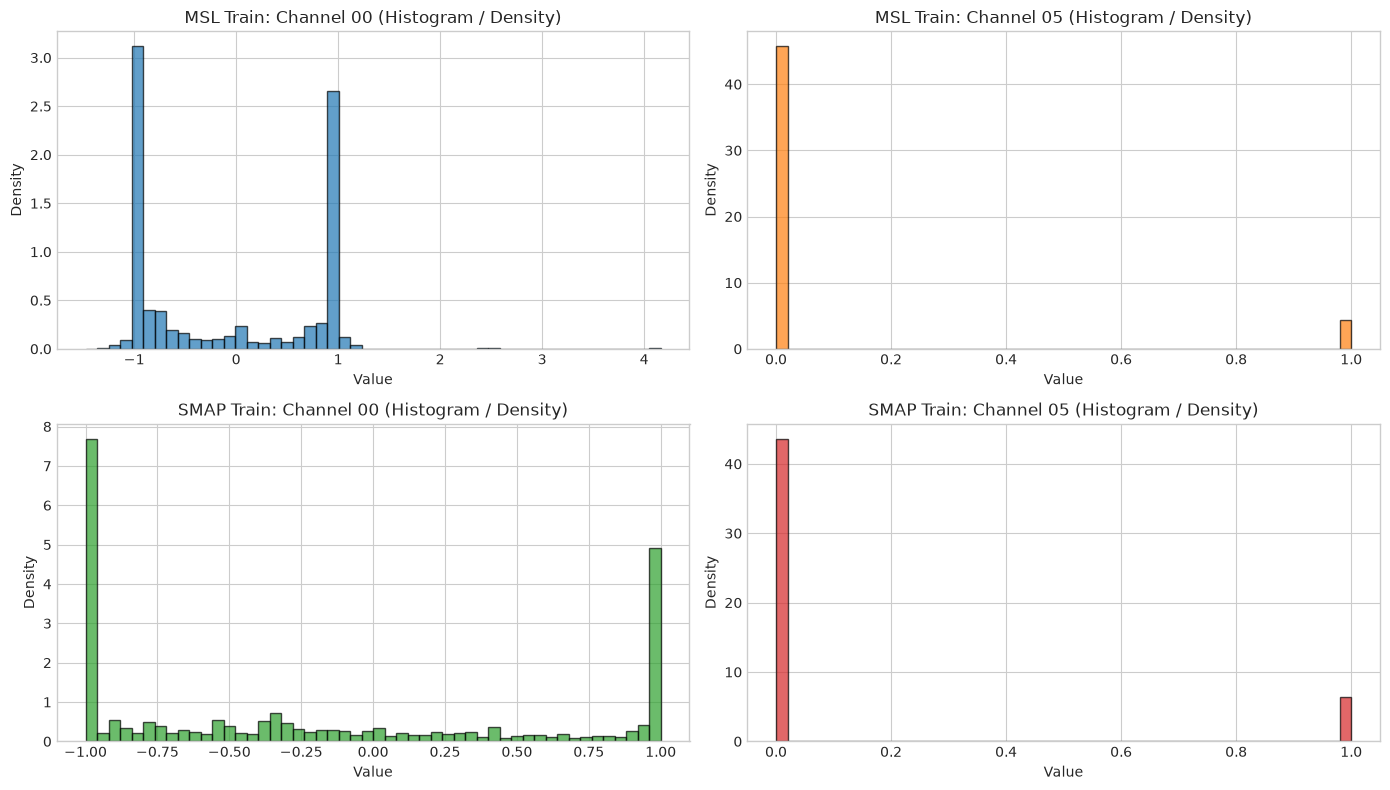

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

# MSL Channel 0 (Primary continuous telemetry)
axes[0, 0].hist(msl_train[:, 0], bins=50, color="#1f77b4", alpha=0.7, edgecolor="black", density=True)
axes[0, 0].set_title("MSL Train: Channel 00 (Histogram / Density)")
axes[0, 0].set_xlabel("Value")
axes[0, 0].set_ylabel("Density")

# MSL Channel 5 (Secondary active feature)
axes[0, 1].hist(msl_train[:, 5], bins=50, color="#ff7f0e", alpha=0.7, edgecolor="black", density=True)
axes[0, 1].set_title("MSL Train: Channel 05 (Histogram / Density)")
axes[0, 1].set_xlabel("Value")
axes[0, 1].set_ylabel("Density")

# SMAP Channel 0 (Primary continuous telemetry)
axes[1, 0].hist(smap_train[:, 0], bins=50, color="#2ca02c", alpha=0.7, edgecolor="black", density=True)
axes[1, 0].set_title("SMAP Train: Channel 00 (Histogram / Density)")
axes[1, 0].set_xlabel("Value")
axes[1, 0].set_ylabel("Density")

# SMAP Channel 5 (Secondary active feature)
axes[1, 1].hist(smap_train[:, 5], bins=50, color="#d62728", alpha=0.7, edgecolor="black", density=True)
axes[1, 1].set_title("SMAP Train: Channel 05 (Histogram / Density)")
axes[1, 1].set_xlabel("Value")
axes[1, 1].set_ylabel("Density")

plt.tight_layout()
plt.show()

## 7. Temporal Behavior (Sequential Index)

Visualize telemetry values plotted across the sample index. No physical timestamps are fabricated.

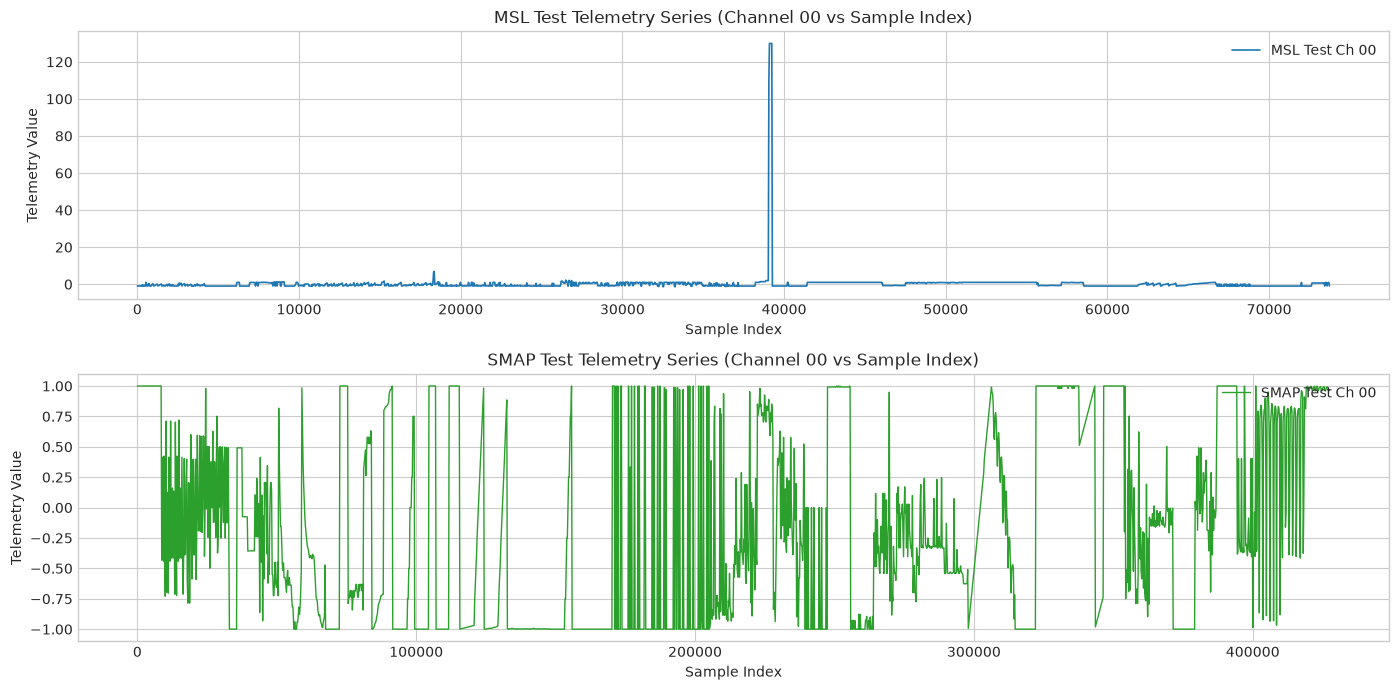

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=False)

# Downsample for responsive rendering
step_msl = max(1, len(msl_test) // 2000)
indices_msl = np.arange(0, len(msl_test), step_msl)
axes[0].plot(indices_msl, msl_test[indices_msl, 0], color="#1f77b4", lw=1.2, label="MSL Test Ch 00")
axes[0].set_title("MSL Test Telemetry Series (Channel 00 vs Sample Index)")
axes[0].set_xlabel("Sample Index")
axes[0].set_ylabel("Telemetry Value")
axes[0].legend(loc="upper right")

step_smap = max(1, len(smap_test) // 2000)
indices_smap = np.arange(0, len(smap_test), step_smap)
axes[1].plot(indices_smap, smap_test[indices_smap, 0], color="#2ca02c", lw=1.0, label="SMAP Test Ch 00")
axes[1].set_title("SMAP Test Telemetry Series (Channel 00 vs Sample Index)")
axes[1].set_xlabel("Sample Index")
axes[1].set_ylabel("Telemetry Value")
axes[1].legend(loc="upper right")

plt.tight_layout()
plt.show()

## 8. Ground-Truth Analysis

Analyze contiguous anomaly windows, total anomalous samples, and duration statistics.

In [8]:
def extract_anomaly_windows(mask):
    diff = np.diff(np.pad(mask.astype(int), (1, 1), 'constant'))
    starts = np.where(diff == 1)[0]
    ends = np.where(diff == -1)[0]
    durations = ends - starts
    return starts, ends, durations

msl_starts, msl_ends, msl_durs = extract_anomaly_windows(msl_test_label)
smap_starts, smap_ends, smap_durs = extract_anomaly_windows(smap_test_label)

def window_stats(name, total_pts, durs):
    return {
        "Dataset": name,
        "Total Test Points": total_pts,
        "Anomalous Points": int(durs.sum()),
        "Anomaly Density (%)": f"{(durs.sum() / total_pts) * 100:.2f}%",
        "Contiguous Windows": len(durs),
        "Min Duration (pts)": int(durs.min()),
        "25th Pct Duration": float(np.percentile(durs, 25)),
        "Median Duration": float(np.median(durs)),
        "75th Pct Duration": float(np.percentile(durs, 75)),
        "90th Pct Duration": float(np.percentile(durs, 90)),
        "Max Duration (pts)": int(durs.max())
    }

df_window_stats = pd.DataFrame([
    window_stats("MSL", len(msl_test_label), msl_durs),
    window_stats("SMAP", len(smap_test_label), smap_durs)
])

df_window_stats.set_index("Dataset").T

Dataset,MSL,SMAP
Total Test Points,73729,427617
Anomalous Points,7766,54696
Anomaly Density (%),10.53%,12.79%
Contiguous Windows,36,67
Min Duration (pts),11,31
25th Pct Duration,70.5,68.5
Median Duration,121.0,131.0
75th Pct Duration,201.0,1246.0
90th Pct Duration,589.0,3059.4
Max Duration (pts),1141,4218


## 9. Anomaly Window Overlay Visualization

Overlay ground-truth anomaly intervals on the test telemetry time series.

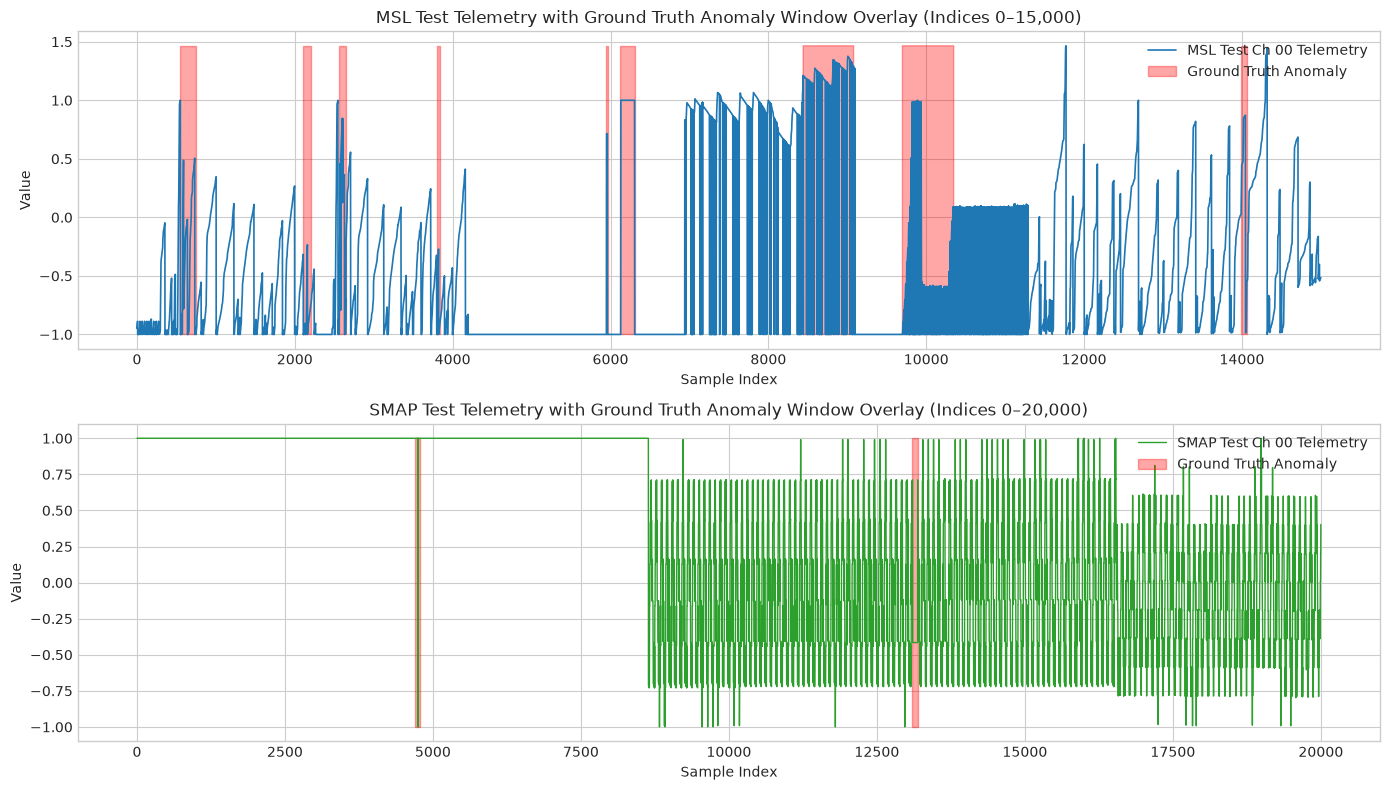

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8))

# Zoom into representative segment of MSL test
zoom_msl_start, zoom_msl_end = 0, 15000
sub_msl = msl_test[zoom_msl_start:zoom_msl_end, 0]
sub_msl_lbl = msl_test_label[zoom_msl_start:zoom_msl_end]
x_msl = np.arange(zoom_msl_start, zoom_msl_end)

axes[0].plot(x_msl, sub_msl, color="#1f77b4", lw=1.2, label="MSL Test Ch 00 Telemetry")
axes[0].fill_between(x_msl, sub_msl.min(), sub_msl.max(), where=sub_msl_lbl, color="red", alpha=0.35, label="Ground Truth Anomaly")
axes[0].set_title("MSL Test Telemetry with Ground Truth Anomaly Window Overlay (Indices 0–15,000)")
axes[0].set_xlabel("Sample Index")
axes[0].set_ylabel("Value")
axes[0].legend(loc="upper right")

# Zoom into representative segment of SMAP test
zoom_smap_start, zoom_smap_end = 0, 20000
sub_smap = smap_test[zoom_smap_start:zoom_smap_end, 0]
sub_smap_lbl = smap_test_label[zoom_smap_start:zoom_smap_end]
x_smap = np.arange(zoom_smap_start, zoom_smap_end)

axes[1].plot(x_smap, sub_smap, color="#2ca02c", lw=1.0, label="SMAP Test Ch 00 Telemetry")
axes[1].fill_between(x_smap, sub_smap.min(), sub_smap.max(), where=sub_smap_lbl, color="red", alpha=0.35, label="Ground Truth Anomaly")
axes[1].set_title("SMAP Test Telemetry with Ground Truth Anomaly Window Overlay (Indices 0–20,000)")
axes[1].set_xlabel("Sample Index")
axes[1].set_ylabel("Value")
axes[1].legend(loc="upper right")

plt.tight_layout()
plt.show()

## 10. Anomaly Morphology Analysis

Examine documented anomaly classifications from the authoritative `labeled_anomalies.csv`.

In [10]:
print("Anomaly class frequencies across all 82 cataloged channels in CSV:")
class_counts = df_labels["class"].value_counts()
display(class_counts)

# Break down counts of pure point vs contextual
point_count = df_labels["class"].apply(lambda x: "point" in x).sum()
contextual_count = df_labels["class"].apply(lambda x: "contextual" in x).sum()

print(f"\nChannels exhibiting point anomalies       : {point_count} ({point_count/len(df_labels)*100:.1f}%)")
print(f"Channels exhibiting contextual anomalies  : {contextual_count} ({contextual_count/len(df_labels)*100:.1f}%)")

Anomaly class frequencies across all 82 cataloged channels in CSV:


class
[point]                                 47
[contextual]                            17
[contextual, contextual]                 6
[point, point]                           4
[contextual, contextual, contextual]     3
[point, contextual]                      3
[point, point, point]                    1
[contextual, point, contextual]          1
Name: count, dtype: int64


Channels exhibiting point anomalies       : 56 (68.3%)
Channels exhibiting contextual anomalies  : 30 (36.6%)


## 11. Train vs Test Distribution Comparison

Quantify empirical distribution shifts between nominal training and test evaluation data across representative channels.

In [11]:
def compare_distributions(tr_col, te_col, label_name):
    return {
        "Channel": label_name,
        "Train Mean": float(np.mean(tr_col)),
        "Test Mean": float(np.mean(te_col)),
        "Mean Delta": float(np.mean(te_col) - np.mean(tr_col)),
        "Train Std": float(np.std(tr_col)),
        "Test Std": float(np.std(te_col)),
        "Std Delta": float(np.std(te_col) - np.std(tr_col)),
        "Train Min": float(np.min(tr_col)),
        "Test Min": float(np.min(te_col)),
        "Train Max": float(np.max(tr_col)),
        "Test Max": float(np.max(te_col))
    }

comp_rows = [
    compare_distributions(msl_train[:, 0], msl_test[:, 0], "MSL Ch 00"),
    compare_distributions(msl_train[:, 5], msl_test[:, 5], "MSL Ch 05"),
    compare_distributions(smap_train[:, 0], smap_test[:, 0], "SMAP Ch 00"),
    compare_distributions(smap_train[:, 5], smap_test[:, 5], "SMAP Ch 05"),
]

df_dist_comp = pd.DataFrame(comp_rows)
df_dist_comp.set_index("Channel").T

Channel,MSL Ch 00,MSL Ch 05,SMAP Ch 00,SMAP Ch 05
Train Mean,-0.088911,0.085807,-0.186839,0.128078
Test Mean,0.238579,0.077758,-0.179944,0.090146
Mean Delta,0.327491,-0.008049,0.006895,-0.037932
Train Std,0.904969,0.280079,0.788575,0.334177
Test Std,6.626504,0.267790,0.775223,0.286391
Std Delta,5.721535,-0.012289,-0.013353,-0.047786
Train Min,-1.477217,0.000000,-1.000000,0.000000
Test Min,-1.424197,0.000000,-1.000000,0.000000
Train Max,4.162651,1.000000,1.000000,1.000000
Test Max,258.108108,1.000000,1.000000,1.000000


## 12. Channel-Level Observations & Boundary Clarifications

> **Critical Boundary Distinction:**
> - The dataset provides **global test label masks** across time steps, plus per-channel anomaly intervals in `labeled_anomalies.csv`.
> - Channel codes (`P-1`, `E-2`, etc.) are anonymized telemetry streams. They do **NOT** map to SpaceGuard's production schemas (`battery_voltage`, `temperature`, `roll`).
> - We do **NOT** assign physical meanings to anonymized channels.

## 13. ML Readiness Assessment & Preparation Recommendations

### Factual Summary
1. **Data Integrity:** 0 missing values, 0 infinities. Highly structured numeric arrays.
2. **Sparse Channels:** In MSL, 22 of 55 channels in the train set have zero variance (inactive command indicators). A preprocessing step must identify and filter zero-variance channels before fitting covariance-based or scale-sensitive algorithms.
3. **Anomaly Density:** MSL contains 10.53% anomalous points; SMAP contains 12.79% anomalous points. Contiguous anomaly windows range from 11 points to over 4,000 points, with a median window of 121–131 points.
4. **Train/Test Regimes:** The training split is strictly nominal with no known faults. Test sets contain real flight anomalies verified by NASA engineers.
5. **Temporal Continuity:** Observations are strictly ordered by sequential index, requiring time-series sliding window feature extraction rather than shuffling.

> **Notice:** **ML MODEL TRAINING HAS NOT STARTED.**\n> This EDA provides the empirical evidence required to formulate Phase 3 data preprocessing and feature engineering.